# 02 · PaletteNet prototype

Goal: check that a CNN can learn per-pixel tone memberships on a single image,
trained only by reconstruction (no labels).

The model is trained with 5 different seeds and compared against a k-means
baseline with the same number of tones, the same new palette and the same metric.
Running several seeds separates consistent model behavior from initialization luck.

In [9]:
import os

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm
import kornia
from PIL import Image

from aquarelab.recolor import assign_by_luminance, hex_to_lab, lab_to_rgb, recolor
from aquarelab.baseline import extract_palette_kmeans

os.makedirs("figures", exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cpu


In [10]:
class ConvBlock(nn.Module):
    def __init__(self, in_ch: int, out_ch: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.net(x)


class PaletteNet(nn.Module):
    """Pretrained encoder + U-Net style decoder that outputs K tone memberships per pixel."""

    def __init__(self, num_tones: int = 8, backbone: str = "resnet34", pretrained: bool = True):
        super().__init__()
        self.encoder = timm.create_model(backbone, features_only=True, pretrained=pretrained)
        channels = self.encoder.feature_info.channels()

        self.up_blocks = nn.ModuleList()
        in_ch = channels[-1]
        for skip_ch in reversed(channels[:-1]):
            self.up_blocks.append(ConvBlock(in_ch + skip_ch, skip_ch))
            in_ch = skip_ch
        self.head = nn.Conv2d(in_ch, num_tones, kernel_size=1)

    def forward(self, x):
        feats = self.encoder(x)
        y = feats[-1]
        for block, skip in zip(self.up_blocks, reversed(feats[:-1])):
            y = F.interpolate(y, size=skip.shape[-2:], mode="bilinear", align_corners=False)
            y = block(torch.cat([y, skip], dim=1))
        y = F.interpolate(y, size=x.shape[-2:], mode="bilinear", align_corners=False)
        return self.head(y).softmax(dim=1)  # (B, K, H, W), sums to 1 per pixel

In [11]:
def palette_from_weights(lab, weights, eps=1e-6):
    """Each tone's color is the weighted mean of the pixels that belong to it. Returns (B, K, 3)."""
    mass = weights.sum(dim=(2, 3)) + eps
    return torch.einsum("bkhw,bchw->bkc", weights, lab) / mass[..., None]


def reconstruct(weights, palette):
    """Rebuild the image using only the palette and the memberships. Returns (B, 3, H, W)."""
    return torch.einsum("bkhw,bkc->bchw", weights, palette)


LAB_SCALE = torch.tensor([1 / 100, 1 / 128, 1 / 128]).view(1, 3, 1, 1)


def reconstruction_loss(lab, recon):
    scale = LAB_SCALE.to(lab.device)
    return F.l1_loss(lab * scale, recon * scale)


def entropy_loss(weights, eps=1e-8):
    """Low entropy pushes each pixel to commit to fewer tones."""
    return -(weights * (weights + eps).log()).sum(dim=1).mean()

In [12]:
img = Image.open("data/florest.jpg").convert("RGB").resize((256, 256))
rgb = torch.from_numpy(np.asarray(img) / 255.0).float().permute(2, 0, 1)[None].to(device)
lab = kornia.color.rgb_to_lab(rgb)

mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)
net_input = (rgb - mean) / std

image_np = rgb[0].permute(1, 2, 0).cpu().numpy()  # (H, W, 3) RGB
lab_np = lab[0].permute(1, 2, 0).cpu().numpy()    # (H, W, 3) Lab

print(f"Input shape: {tuple(rgb.shape)}")

Input shape: (1, 3, 256, 256)


In [13]:
SEEDS = [0, 1, 2, 3, 4]
NUM_TONES = 8
STEPS = 200
LR = 1e-3
ENTROPY_WEIGHT = 0.01
DEAD_THRESHOLD = 0.01  # a tone covering less than 1% of the image is considered dead

new_palette = hex_to_lab([
    "#264653", "#2a9d8f", "#8ab17d", "#e9c46a",
    "#f4a261", "#e76f51", "#b56576", "#6d597a",
])

In [14]:
def l1_lab(lab_a, lab_b):
    scale = np.array([1 / 100, 1 / 128, 1 / 128])
    return np.abs((lab_a - lab_b) * scale).mean()


def to_hwc(t):
    """(1, C, H, W) tensor -> (H, W, C) numpy array."""
    return t[0].permute(1, 2, 0).detach().cpu().numpy()


def train_palette_net(seed):
    torch.manual_seed(seed)
    model = PaletteNet(num_tones=NUM_TONES).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)

    history = []
    model.train()
    for step in range(STEPS):
        weights = model(net_input)
        palette = palette_from_weights(lab, weights)
        recon = reconstruct(weights, palette)

        loss = reconstruction_loss(lab, recon) + ENTROPY_WEIGHT * entropy_loss(weights)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        history.append(loss.item())

    model.eval()
    with torch.no_grad():
        weights = model(net_input)
        palette = palette_from_weights(lab, weights)
        recon = reconstruct(weights, palette)

    weights_np = to_hwc(weights)
    return {
        "name": f"PaletteNet (seed {seed})",
        "history": history,
        "weights": weights_np,
        "palette": palette[0].cpu().numpy(),
        "recon_lab": to_hwc(recon),
        "usage": weights_np.mean(axis=(0, 1)),
    }


def evaluate(run):
    """Add the same metrics and recoloring to any method, so all runs are compared equally."""
    run["recon_l1"] = l1_lab(lab_np, run["recon_lab"])
    run["recon_rgb"] = lab_to_rgb(run["recon_lab"])
    run["dead"] = int((run["usage"] < DEAD_THRESHOLD).sum())
    matched = assign_by_luminance(run["palette"], new_palette)
    run["recolored"] = recolor(image_np, run["weights"], run["palette"], matched)
    return run


def show_grid(images, titles, path, suptitle=None, cols=4, size=4):
    rows = int(np.ceil(len(images) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, image, title in zip(axes, images, titles):
        ax.imshow(image)
        ax.set_title(title)
    if suptitle:
        fig.suptitle(suptitle, fontsize=16, fontweight="bold")
    plt.tight_layout()
    plt.savefig(path, dpi=120, bbox_inches="tight")
    plt.show()

In [15]:
runs = []
for seed in SEEDS:
    run = evaluate(train_palette_net(seed))
    runs.append(run)
    print(
        f"{run['name']:<22} | final train loss (recon + entropy) {run['history'][-1]:.4f} "
        f"| recon L1 {run['recon_l1']:.4f} | dead tones {run['dead']}"
    )

PaletteNet (seed 0)    | final train loss (recon + entropy) 0.0240 | recon L1 0.0199 | dead tones 2
PaletteNet (seed 1)    | final train loss (recon + entropy) 0.0246 | recon L1 0.0212 | dead tones 3
PaletteNet (seed 2)    | final train loss (recon + entropy) 0.0246 | recon L1 0.0213 | dead tones 3
PaletteNet (seed 3)    | final train loss (recon + entropy) 0.0212 | recon L1 0.0170 | dead tones 1
PaletteNet (seed 4)    | final train loss (recon + entropy) 0.0248 | recon L1 0.0212 | dead tones 3


In [16]:
km_palette, km_weights = extract_palette_kmeans(image_np, k=NUM_TONES)
kmeans_run = evaluate({
    "name": f"k-means (k={NUM_TONES})",
    "weights": km_weights,
    "palette": km_palette,
    "recon_lab": km_weights @ km_palette,
    "usage": km_weights.mean(axis=(0, 1)),
})

all_runs = [kmeans_run] + runs

In [17]:
print(f"{'Method':<22} | {'Recon L1':>8} | {'Dead tones':>10}")
print("-" * 46)
for run in all_runs:
    print(f"{run['name']:<22} | {run['recon_l1']:>8.4f} | {run['dead']:>10d}")

net_l1 = np.array([r["recon_l1"] for r in runs])
net_dead = np.array([r["dead"] for r in runs])
print("-" * 46)
print(f"PaletteNet recon L1: {net_l1.mean():.4f} ± {net_l1.std():.4f}")
print(f"PaletteNet dead tones: mean {net_dead.mean():.1f}, min {net_dead.min()}, max {net_dead.max()}")

Method                 | Recon L1 | Dead tones
----------------------------------------------
k-means (k=8)          |   0.0124 |          0
PaletteNet (seed 0)    |   0.0199 |          2
PaletteNet (seed 1)    |   0.0212 |          3
PaletteNet (seed 2)    |   0.0213 |          3
PaletteNet (seed 3)    |   0.0170 |          1
PaletteNet (seed 4)    |   0.0212 |          3
----------------------------------------------
PaletteNet recon L1: 0.0201 ± 0.0016
PaletteNet dead tones: mean 2.4, min 1, max 3


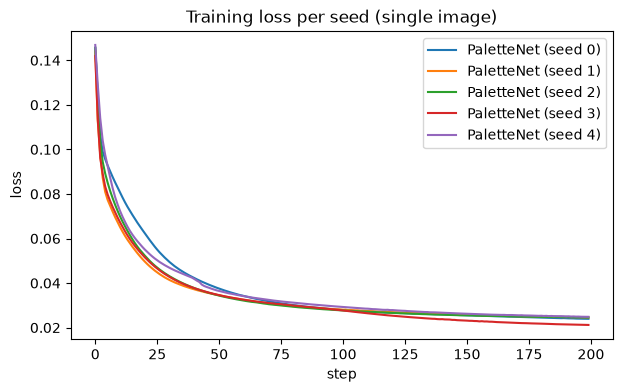

In [18]:
fig, ax = plt.subplots(figsize=(7, 4))
for run in runs:
    ax.plot(run["history"], label=run["name"])
ax.set_title("Training loss per seed (single image)")
ax.set_xlabel("step")
ax.set_ylabel("loss")
ax.legend()
plt.savefig("figures/02_loss.png", dpi=120, bbox_inches="tight")
plt.show()

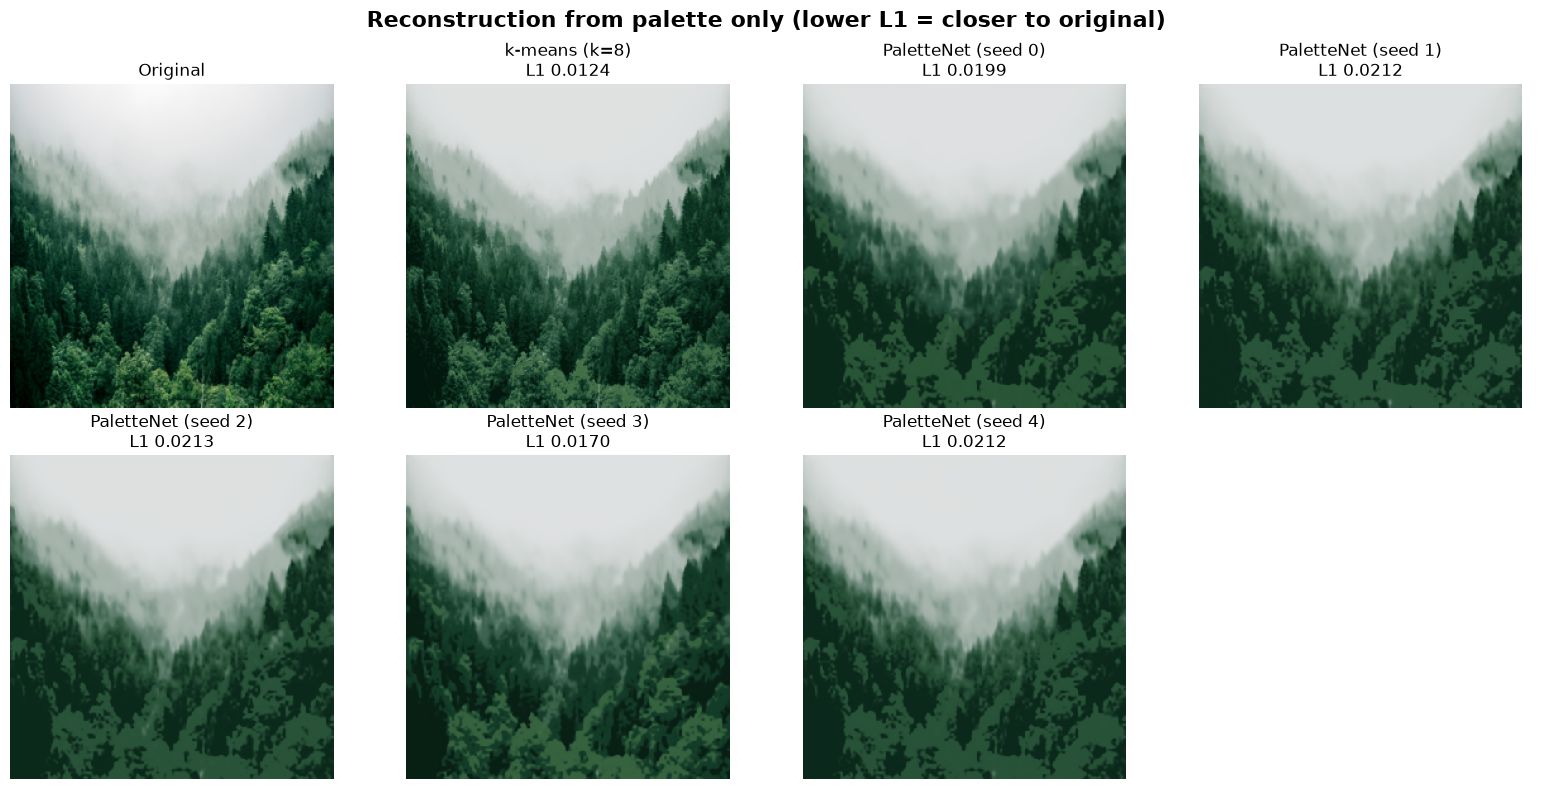

In [19]:
show_grid(
    [image_np] + [r["recon_rgb"] for r in all_runs],
    ["Original"] + [f"{r['name']}\nL1 {r['recon_l1']:.4f}" for r in all_runs],
    "figures/02_reconstruction.png",
    suptitle="Reconstruction from palette only (lower L1 = closer to original)",
)

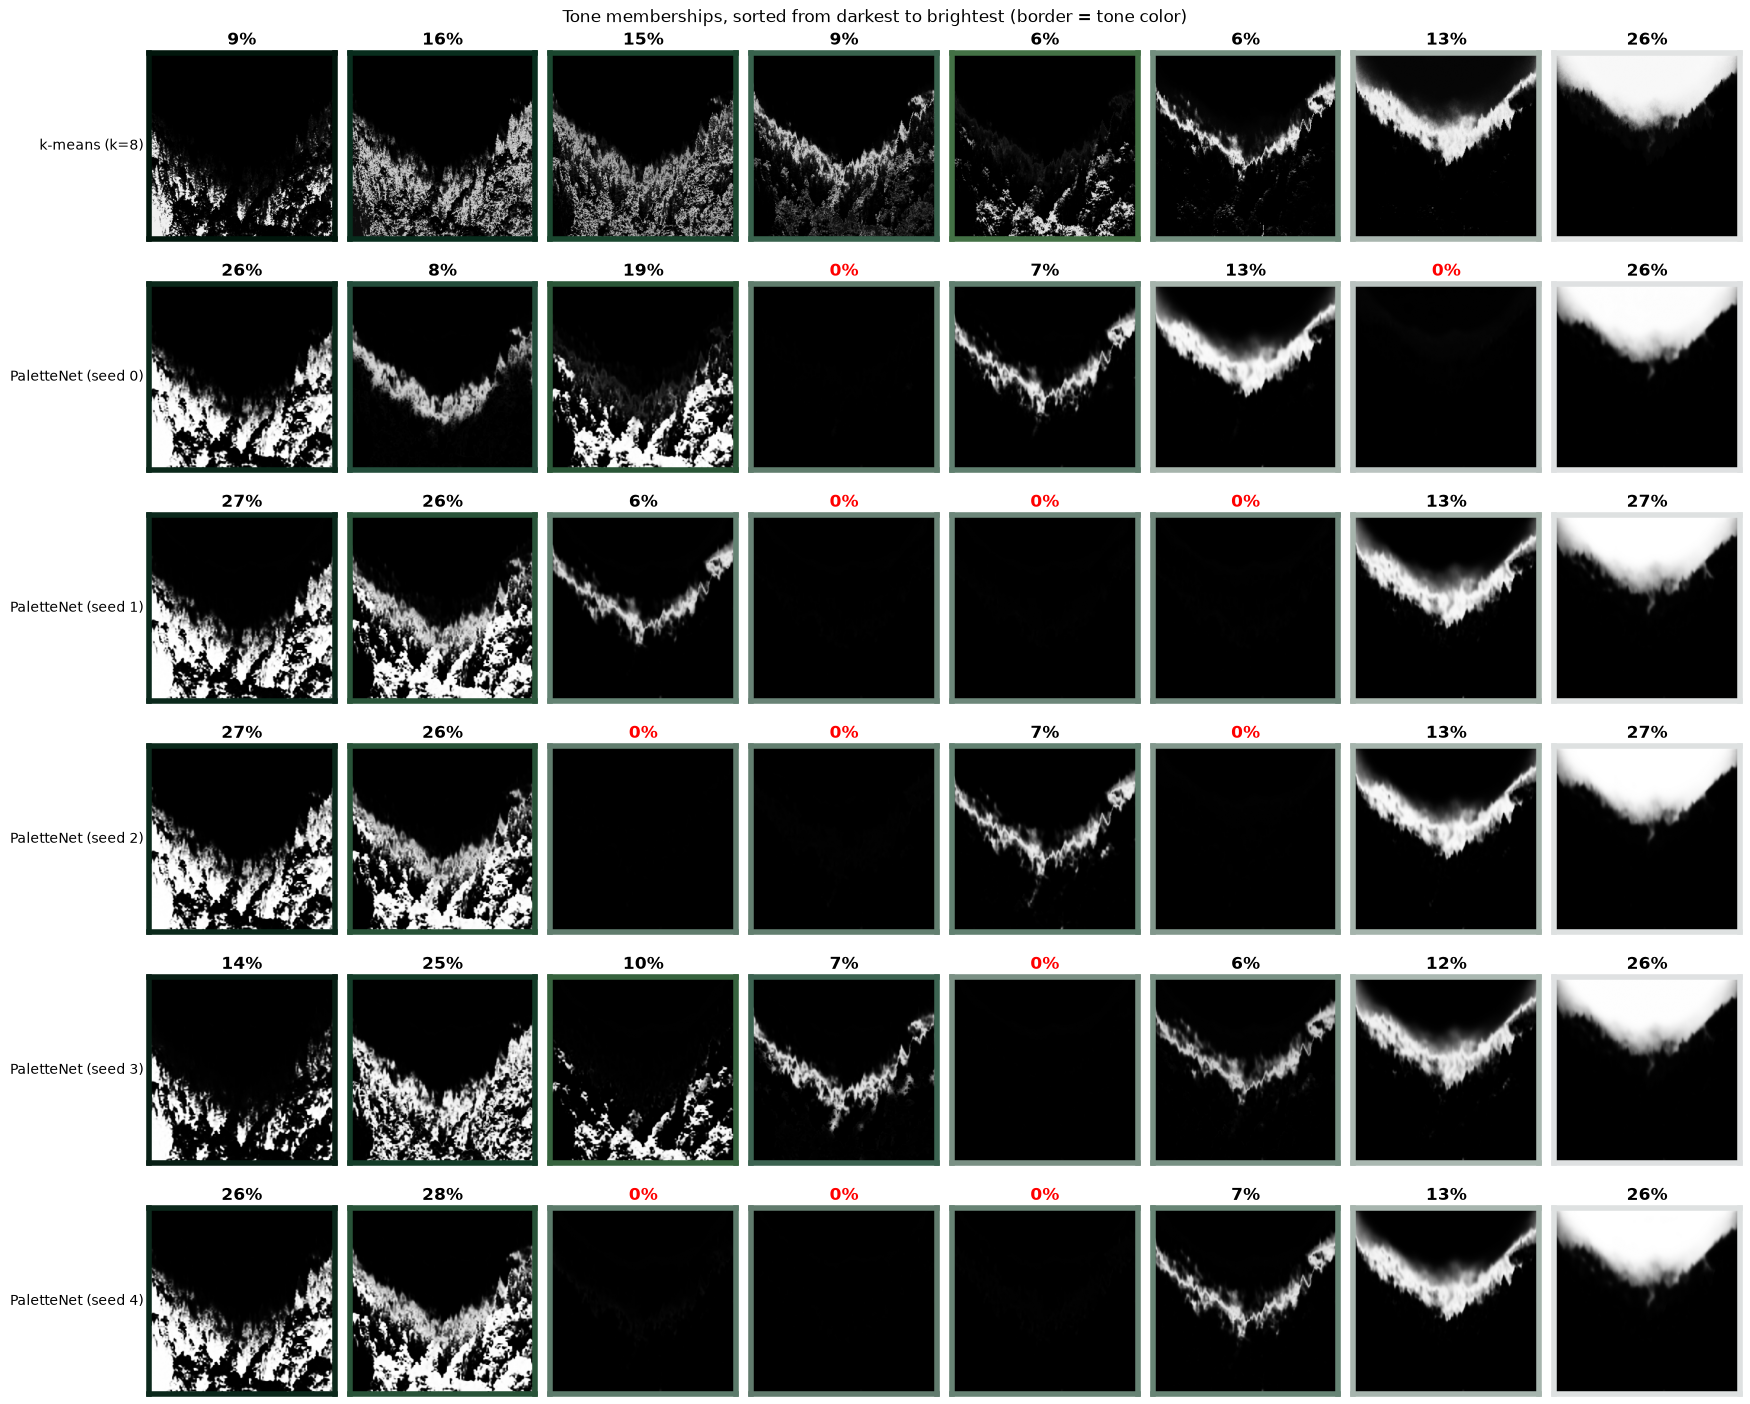

In [20]:
fig, axes = plt.subplots(
    len(all_runs), NUM_TONES, figsize=(2.2 * NUM_TONES, 2.4 * len(all_runs))
)
for r, run in enumerate(all_runs):
    order = np.argsort(run["palette"][:, 0])  # darkest to brightest
    for c, tone in enumerate(order):
        ax = axes[r, c]
        ax.imshow(run["weights"][..., tone], cmap="gray", vmin=0, vmax=1)
        swatch = lab_to_rgb(run["palette"][tone][None, None, :])[0, 0]
        is_dead = run["usage"][tone] < DEAD_THRESHOLD
        ax.set_title(
            f"{run['usage'][tone]:.0%}",
            color="red" if is_dead else "black",
            fontweight="bold",
        )
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_edgecolor(swatch)
            spine.set_linewidth(4)
    axes[r, 0].set_ylabel(run["name"], rotation=0, ha="right", va="center", fontsize=10)

fig.suptitle("Tone memberships, sorted from darkest to brightest (border = tone color)")
plt.tight_layout()
plt.savefig("figures/02_tone_maps.png", dpi=120, bbox_inches="tight")
plt.show()

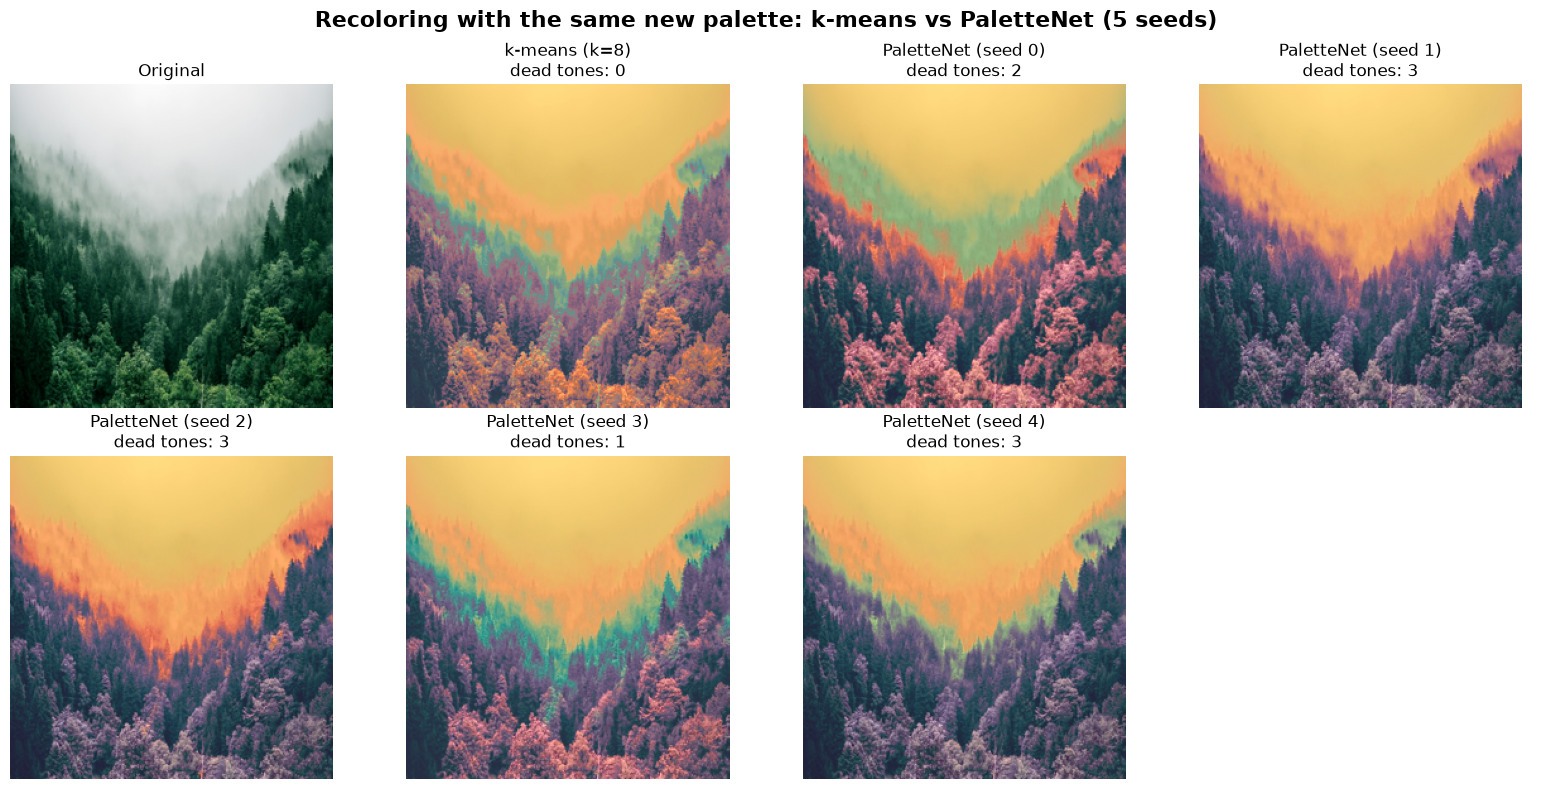

In [21]:
show_grid(
    [image_np] + [r["recolored"] for r in all_runs],
    ["Original"] + [f"{r['name']}\ndead tones: {r['dead']}" for r in all_runs],
    "figures/02_recolor_comparison.png",
    suptitle="Recoloring with the same new palette: k-means vs PaletteNet (5 seeds)",
)

## Conclusions

**Dead tones happen in every seed and drive most of the error.** PaletteNet
loses 1 to 3 of its 8 tones (mean 2.4), while k-means keeps all 8. Fewer dead
tones means lower error: seed 3 has 1 dead tone and the best L1 (0.0170), while
the three seeds with 3 dead tones all sit around 0.0212.

**Reconstruction error is consistent across seeds and clearly worse than
k-means.** PaletteNet reaches 0.0201 ± 0.0016, against 0.0124 for k-means. The
gap is several times larger than the variation between seeds, so this is not
noise. It is expected, since k-means directly minimizes color distance.

**Stripes at the fog border are consistent behavior, not luck.** The three
brightest tones are nearly identical in every seed and in k-means: a thin band
(~6-7%), a transition band (~13%) and the fog itself (~26-27%). Both methods
slice the fog gradient into the same layers, and recoloring turns those layers
into visible stripes.

**Visual differences between seeds come from dead tones, not better
segmentation.** Seeds 1, 2 and 4 look smoother at the fog border, but they are
the ones with 3 dead tones. Luminance-based assignment still hands new colors
to dead tones, so they absorb the middle colors (teal, green) and the visible
bands receive neighboring warm colors. Seed 3, with almost all tones alive,
shows the same teal stripe as k-means.

**The one consistent advantage of PaletteNet is spatial coherence.** k-means
tone maps in the forest are speckled, because it groups pixels by color alone.
PaletteNet maps form continuous regions that follow treetops and groups of
trees. In the recolored images this shows up as coherent pink and purple
patches, instead of scattered orange speckle. The cost: PaletteNet spends three
tones on the fog gradient and leaves only two or three for the forest, so the
forest reconstruction is flat.